In [ ]:
"""
Native Arizona fish occurrence database (student research project).

Three steps, run in order:
  fetch    -> asks GBIF for occurrence records of native Arizona fishes and
              stores them (plus the datasets they came from) in az_fish.db
  analyze  -> reads the database, prints a summary table, saves 2 figures
  site     -> builds index.html: a self-contained, paper-style write-up with
              your REAL numbers, figures, tables, an interactive map, sources
              and limitations (also writes map.html on its own)

Terminal:  python az_fish.py fetch   (then analyze, then site)
Notebook:  paste this whole file into the first cell and run it, then call
           cmd_fetch(), cmd_analyze(), cmd_site() in separate cells.
           After the first fetch you only need to re-run analyze + site.

Data source: GBIF (gbif.org). For formal citation, create a GBIF download
(free account) and cite its DOI instead of the search API.
"""

import base64
import datetime
import html
import json
import math
import sqlite3
import sys
import time

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from folium.plugins import FastMarkerCluster, HeatMap
from matplotlib.patches import Rectangle

# ---- Edit these -----------------------------------------------------------
AUTHOR = "Sabian Henderson"
AFFILIATION = "Northern Arizona University"
PROJECT_TITLE = "Occurrence Records of Native Arizona Fishes in GBIF"
REPO_URL = ""   # e.g. "https://github.com/yourname/az-fish" (leave blank to omit)
NOTES = ""      # optional: your own interpretation, 2-3 sentences. Blank = section omitted.
# ---------------------------------------------------------------------------

DB_PATH = "az_fish.db"
GBIF = "https://api.gbif.org/v1"

# Species to pull. The fetch step prints what GBIF matched each name to --
# check those, and edit this list to match your interests.
SPECIES = [
    "Gila cypha",
    "Xyrauchen texanus",
    "Gila elegans",
    "Ptychocheilus lucius",
    "Catostomus latipinnis",
    "Rhinichthys osculus",
    "Oncorhynchus apache",
    "Cyprinodon macularius",
]
COMMON = {
    "Gila cypha": "Humpback chub",
    "Xyrauchen texanus": "Razorback sucker",
    "Gila elegans": "Bonytail",
    "Ptychocheilus lucius": "Colorado pikeminnow",
    "Catostomus latipinnis": "Flannelmouth sucker",
    "Rhinichthys osculus": "Speckled dace",
    "Oncorhynchus apache": "Apache trout",
    "Cyprinodon macularius": "Desert pupfish",
}

# Okabe-Ito colour-blind-safe palette + distinct marker shapes
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#7A6A00", "#444444"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]

# Approximate bounding box of Arizona (degrees), used for map context + a data check
AZ_W, AZ_E, AZ_S, AZ_N = -114.82, -109.045, 31.33, 37.0


# ------------------------------------------------------------------ database
def init_db(conn):
    conn.executescript(
        """
        CREATE TABLE IF NOT EXISTS species (
            taxon_key    INTEGER PRIMARY KEY,
            query_name   TEXT,
            matched_name TEXT
        );
        CREATE TABLE IF NOT EXISTS datasets (
            dataset_key  TEXT PRIMARY KEY,
            title        TEXT
        );
        CREATE TABLE IF NOT EXISTS occurrences (
            gbif_key        INTEGER PRIMARY KEY,   -- unique per record, prevents duplicates
            taxon_key       INTEGER REFERENCES species(taxon_key),
            event_date      TEXT,
            year            INTEGER,
            latitude        REAL,
            longitude       REAL,
            basis_of_record TEXT,
            dataset_key     TEXT REFERENCES datasets(dataset_key)
        );
        """
    )


def match_species(name):
    """Ask GBIF which taxon our name refers to. Returns (taxon_key, matched_name) or None."""
    r = requests.get(f"{GBIF}/species/match", params={"name": name}, timeout=30)
    r.raise_for_status()
    data = r.json()
    if "usageKey" not in data:
        return None
    return data["usageKey"], data.get("scientificName", name)


def fetch_occurrences(taxon_key, state="Arizona"):
    """Yield occurrence records for one taxon, paging through GBIF's results."""
    offset, limit = 0, 300  # 300 is GBIF's maximum page size
    while True:
        r = requests.get(
            f"{GBIF}/occurrence/search",
            params={
                "taxonKey": taxon_key,
                "country": "US",
                "stateProvince": state,
                "hasCoordinate": "true",
                "limit": limit,
                "offset": offset,
            },
            timeout=60,
        )
        r.raise_for_status()
        page = r.json()
        yield from page.get("results", [])
        if page.get("endOfRecords", True):
            break
        offset += limit
        time.sleep(0.5)  # be polite to the free API


def dataset_title(key):
    """Look up the human-readable title of a GBIF dataset (falls back to the key)."""
    try:
        r = requests.get(f"{GBIF}/dataset/{key}", timeout=30)
        r.raise_for_status()
        return r.json().get("title", key)
    except requests.RequestException:
        return key


def cmd_fetch():
    conn = sqlite3.connect(DB_PATH)
    init_db(conn)
    for name in SPECIES:
        match = match_species(name)
        if match is None:
            print(f"!! GBIF could not match '{name}' - check the spelling")
            continue
        taxon_key, matched = match
        print(f"{name}  ->  GBIF matched: {matched} (key {taxon_key})")
        conn.execute(
            "INSERT OR REPLACE INTO species VALUES (?, ?, ?)", (taxon_key, name, matched)
        )
        n = 0
        for rec in fetch_occurrences(taxon_key):
            conn.execute(
                "INSERT OR IGNORE INTO occurrences VALUES (?,?,?,?,?,?,?,?)",
                (
                    rec["key"],
                    taxon_key,
                    rec.get("eventDate"),
                    rec.get("year"),
                    rec.get("decimalLatitude"),
                    rec.get("decimalLongitude"),
                    rec.get("basisOfRecord"),
                    rec.get("datasetKey"),
                ),
            )
            n += 1
        conn.commit()
        print(f"   stored {n} records")

    missing = [
        k for (k,) in conn.execute(
            "SELECT DISTINCT dataset_key FROM occurrences "
            "WHERE dataset_key IS NOT NULL AND dataset_key NOT IN (SELECT dataset_key FROM datasets)"
        )
    ]
    print(f"Looking up titles for {len(missing)} source datasets...")
    for key in missing:
        conn.execute("INSERT OR REPLACE INTO datasets VALUES (?, ?)", (key, dataset_title(key)))
        time.sleep(0.2)
    conn.commit()
    conn.close()


def load_records(conn):
    return pd.read_sql_query(
        "SELECT o.*, s.query_name AS species FROM occurrences o JOIN species s USING (taxon_key)",
        conn,
    )


# ------------------------------------------------------------------- figures
def species_by_count(df):
    return df["species"].value_counts().index.tolist()


def style_axes(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(labelsize=8)


def fig_decades(df):
    """Figure 1: one small panel per species (own y-axis, so rare species stay visible)."""
    d = df.dropna(subset=["year"]).copy()
    d["decade"] = (d["year"] // 10 * 10).astype(int)
    species = species_by_count(d)
    decades = list(range(int(d["decade"].min()), int(d["decade"].max()) + 10, 10))
    ncols = 4
    nrows = math.ceil(len(species) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 2.9 * nrows), sharex=True)
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        if i >= len(species):
            ax.set_visible(False)
            continue
        sp = species[i]
        counts = d[d["species"] == sp].groupby("decade").size().reindex(decades, fill_value=0)
        ax.bar(range(len(decades)), counts.values, color=PALETTE[i % len(PALETTE)],
               edgecolor="black", linewidth=0.4)
        ax.set_title(sp, fontsize=9, style="italic", loc="left")
        ax.set_title(f"n = {counts.sum():,}", fontsize=8, loc="right")
        ax.set_xticks(range(len(decades)))
        ax.set_xticklabels([f"{x}s" for x in decades], rotation=90, fontsize=7)
        ax.tick_params(labelbottom=True)
        if i % ncols == 0:
            ax.set_ylabel("Records", fontsize=8)
        style_axes(ax)
    fig.tight_layout()
    fig.savefig("records_by_decade.png", dpi=200, bbox_inches="tight")
    plt.close(fig)


def outside_box(df):
    g = df.dropna(subset=["latitude", "longitude"])
    return g[(g["longitude"] < AZ_W) | (g["longitude"] > AZ_E) |
             (g["latitude"] < AZ_S) | (g["latitude"] > AZ_N)]


MAP_X = (AZ_W - 0.7, AZ_E + 0.7)
MAP_Y = (AZ_S - 0.4, AZ_N + 0.4)


def n_clipped(df):
    """Records whose coordinates fall outside the plotted map area."""
    g = df.dropna(subset=["latitude", "longitude"])
    return int(((g["longitude"] < MAP_X[0]) | (g["longitude"] > MAP_X[1]) |
                (g["latitude"] < MAP_Y[0]) | (g["latitude"] > MAP_Y[1])).sum())


def fig_map(df):
    """Figure 2: record locations; rarest species drawn last so they stay visible."""
    g = df.dropna(subset=["latitude", "longitude"])
    order = species_by_count(g)
    fig, ax = plt.subplots(figsize=(8.5, 7))
    ax.add_patch(Rectangle((AZ_W, AZ_S), AZ_E - AZ_W, AZ_N - AZ_S, fill=False,
                           linestyle="--", linewidth=0.9, edgecolor="gray"))
    for i, sp in reversed(list(enumerate(order))):  # most abundant first, rarest on top
        s = g[g["species"] == sp]
        ax.scatter(s["longitude"], s["latitude"], s=18, alpha=0.75,
                   color=PALETTE[i % len(PALETTE)], marker=MARKERS[i % len(MARKERS)],
                   edgecolors="white", linewidths=0.3, label=sp)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1.01, 0.5),
              frameon=False, prop={"style": "italic", "size": 8}, markerscale=1.4)
    ax.set_xlim(*MAP_X)
    ax.set_ylim(*MAP_Y)
    ax.set_aspect(1 / np.cos(np.radians((AZ_S + AZ_N) / 2)))  # roughly equal ground distances
    ax.set_xlabel("Longitude (°)", fontsize=9)
    ax.set_ylabel("Latitude (°)", fontsize=9)
    ax.grid(color="#dddddd", linewidth=0.5)
    style_axes(ax)
    fig.tight_layout()
    fig.savefig("record_locations.png", dpi=200, bbox_inches="tight")
    plt.close(fig)


def cmd_analyze():
    conn = sqlite3.connect(DB_PATH)
    df = load_records(conn)
    conn.close()
    if df.empty:
        print("Database is empty - run fetch first.")
        return
    summary = (
        df.groupby("species")
        .agg(records=("gbif_key", "count"), first_year=("year", "min"), last_year=("year", "max"))
        .sort_values("records", ascending=False)
    )
    print(summary)
    summary.to_csv("species_summary.csv")
    fig_decades(df)
    fig_map(df)
    n_out = len(outside_box(df))
    print(f"Records outside the Arizona bounding box: {n_out} ({n_clipped(df)} beyond the map margins, not drawn)")
    print("Saved species_summary.csv, records_by_decade.png, record_locations.png")


# ---------------------------------------------------------------------- map
# Base maps. None of these needs an API key. (The old OpenStreetMap-only map showed a
# blank grey background inside Colab's sandboxed preview; offering several providers
# means at least one will load anywhere.)
BASEMAPS = [
    ("CARTO Positron (light)", "https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png",
     "&copy; OpenStreetMap contributors &copy; CARTO", "abcd"),
    ("Esri World Topographic",
     "https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
     "Tiles &copy; Esri", None),
    ("Esri Satellite",
     "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
     "Tiles &copy; Esri &mdash; Source: Esri, Maxar, Earthstar Geographics, and the GIS User Community", None),
    ("OpenStreetMap", "https://tile.openstreetmap.org/{z}/{x}/{y}.png",
     "&copy; OpenStreetMap contributors", None),
]


def build_map(df):
    """Interactive Leaflet map: density heat layer + one toggleable, clustered layer per species."""
    g = df.dropna(subset=["latitude", "longitude"])
    order = species_by_count(g)
    m = folium.Map(location=[34.2, -111.7], zoom_start=6, tiles=None, control_scale=True)
    for i, (name, url, attr, subs) in enumerate(BASEMAPS):
        kw = {"subdomains": subs} if subs else {}
        folium.TileLayer(tiles=url, attr=attr, name=name, overlay=False, control=True,
                         show=(i == 0), max_zoom=19, **kw).add_to(m)

    heat = folium.FeatureGroup(name="Record density (heat map, all species)", show=True)
    HeatMap(g[["latitude", "longitude"]].values.tolist(), radius=11, blur=15, min_opacity=0.35).add_to(heat)
    heat.add_to(m)

    for i, sp in enumerate(order):
        color = PALETTE[i % len(PALETTE)]
        sub = g[g["species"] == sp]
        rows = []
        for r in sub.itertuples():
            basis = r.basis_of_record.replace("_", " ").lower() if isinstance(r.basis_of_record, str) else "unknown"
            rows.append([round(float(r.latitude), 5), round(float(r.longitude), 5),
                         "unknown" if pd.isna(r.year) else int(r.year), basis])
        label = f"{sp} ({COMMON.get(sp, '')}, n={len(sub):,})"
        callback = """
        function (row) {
            var icon = L.divIcon({className: '', iconSize: [13, 13],
                html: '<div style="background:%s;width:11px;height:11px;border-radius:50%%;border:1.5px solid #fff;box-shadow:0 0 2px #000"></div>'});
            var marker = L.marker(new L.LatLng(row[0], row[1]), {icon: icon});
            marker.bindPopup("<i>" + %s + "</i><br>Year: " + row[2] + "<br>Record type: " + row[3]);
            return marker;
        }
        """ % (color, json.dumps(sp))
        grp = folium.FeatureGroup(name=label, show=False)
        grp.add_child(FastMarkerCluster(data=rows, callback=callback))
        m.add_child(grp)

    items = "".join(
        f'<div><span style="display:inline-block;width:10px;height:10px;border-radius:50%;background:{PALETTE[i % len(PALETTE)]};'
        f'margin-right:6px"></span><i>{html.escape(sp)}</i></div>' for i, sp in enumerate(order)
    )
    legend = (
        '<div style="position:fixed;bottom:24px;left:12px;z-index:9999;background:rgba(255,255,255,.92);'
        'padding:8px 10px;border:1px solid #999;border-radius:4px;font:12px Georgia,serif;line-height:1.5">'
        '<b>Species layers</b> (toggle at top right)' + items +
        '<div style="margin-top:4px;color:#555">Heat layer = density of records, not abundance</div></div>'
    )
    m.get_root().html.add_child(folium.Element(legend))
    m.fit_bounds([[AZ_S, AZ_W], [AZ_N, AZ_E]])
    folium.LayerControl(collapsed=False, position="topright").add_to(m)
    return m.get_root().render()


def cmd_map():
    """Write map.html (a standalone interactive map) from the database."""
    conn = sqlite3.connect(DB_PATH)
    df = load_records(conn)
    conn.close()
    if df.empty:
        print("Database is empty - run fetch first.")
        return
    with open("map.html", "w", encoding="utf-8") as f:
        f.write(build_map(df))
    print("Wrote map.html - download it and open it in your browser to check the base map.")


# --------------------------------------------------------------------- site
CSS = """
body{font-family:Georgia,"Times New Roman",serif;max-width:780px;margin:2.5rem auto;padding:0 1.2rem;
     line-height:1.55;color:#111;font-size:17px}
h1{font-size:1.75rem;text-align:center;margin:0 0 .4rem;line-height:1.25}
.byline{text-align:center;margin:0}
.status{text-align:center;font-size:.9rem;color:#555;font-style:italic;margin:.2rem 0 0}
.abstract{border-top:1px solid #999;border-bottom:1px solid #999;padding:.8rem 0;margin:1.6rem 0}
.abstract b{font-variant:small-caps;letter-spacing:.03em}
h2{font-size:1.2rem;border-bottom:1px solid #ccc;padding-bottom:.2rem;margin-top:2.2rem}
table{border-collapse:collapse;width:100%;font-size:.88rem}
thead th{border-top:2px solid #111;border-bottom:1px solid #111;text-align:left;padding:.35rem .5rem}
tbody td{padding:.3rem .5rem;vertical-align:top}
tbody tr:last-child td{border-bottom:2px solid #111}
.num{text-align:right}
.cap{font-size:.9rem;margin:1.3rem 0 .35rem;break-after:avoid;page-break-after:avoid}
figure{margin:1.6rem 0}
figure img{width:100%;height:auto}
.map{width:100%;height:560px;border:1px solid #999}
figcaption{font-size:.9rem;margin-top:.4rem}
.wide{overflow-x:auto}
.refs{font-size:.92rem;padding-left:1.2rem}
footer{margin-top:2.5rem;font-size:.82rem;color:#555;border-top:1px solid #ccc;padding-top:.6rem}
@media print{body{margin:1cm;font-size:11pt}figure,table{page-break-inside:avoid}}
"""


def embed(path):
    try:
        with open(path, "rb") as f:
            return "data:image/png;base64," + base64.b64encode(f.read()).decode()
    except FileNotFoundError:
        raise SystemExit(f"{path} not found - run cmd_analyze() before cmd_site().")


def table_html(headers, rows, num_cols=()):
    """headers: list of str; rows: list of lists of ready-to-insert HTML; num_cols: right-aligned columns."""
    th = "".join(f'<th class="{"num" if i in num_cols else ""}">{h}</th>' for i, h in enumerate(headers))
    body = "".join(
        "<tr>" + "".join(f'<td class="{"num" if i in num_cols else ""}">{c}</td>' for i, c in enumerate(r)) + "</tr>"
        for r in rows
    )
    return f'<div class="wide"><table><thead><tr>{th}</tr></thead><tbody>{body}</tbody></table></div>'


def fmt_year(x):
    return str(int(x)) if pd.notna(x) else "&ndash;"


def cmd_site():
    """Write index.html (self-contained: figures are embedded) from what is in your database."""
    conn = sqlite3.connect(DB_PATH)
    df = load_records(conn)
    sources = pd.read_sql_query(
        """
        SELECT COALESCE(d.title, o.dataset_key) AS title, COUNT(*) AS n
        FROM occurrences o LEFT JOIN datasets d USING (dataset_key)
        GROUP BY o.dataset_key ORDER BY COUNT(*) DESC
        """,
        conn,
    )
    conn.close()
    if df.empty:
        print("Database is empty - run fetch and analyze first.")
        return

    n, today = len(df), datetime.date.today().isoformat()
    n_sp = df["species"].nunique()
    years = df["year"].dropna()
    span = f"{int(years.min())}&ndash;{int(years.max())}" if not years.empty else "n/a"
    n_noyear = int(df["year"].isna().sum())
    counts = df["species"].value_counts()
    top_sp, top_n = counts.index[0], int(counts.iloc[0])
    n_ds = len(sources)
    n_out = len(outside_box(df))
    n_clip = n_clipped(df)
    map_html = build_map(df)
    with open("map.html", "w", encoding="utf-8") as f:
        f.write(map_html)
    basis = df["basis_of_record"].fillna("UNKNOWN").value_counts()
    pct_spec = 100 * basis.get("PRESERVED_SPECIMEN", 0) / n
    decade_tot = (years // 10 * 10).astype(int).value_counts()
    peak_dec, peak_n = int(decade_tot.idxmax()), int(decade_tot.max())

    abstract = (
        f"I compiled {n:,} georeferenced occurrence records for {n_sp} native Arizona fish species from the "
        f"Global Biodiversity Information Facility (GBIF), spanning {span}. "
        f"<i>{html.escape(top_sp)}</i> has the most records ({top_n:,}; {100 * top_n / n:.0f}% of the total). "
        f"Records come from {n_ds} contributing datasets"
        + (f", and {pct_spec:.0f}% are preserved specimens" if pct_spec > 0 else "")
        + ". This page summarizes where and when each species has been recorded and describes limits on "
        "interpreting record counts."
    )

    # Table 1: study species
    sp_rows = []
    for sp in counts.index:
        g = df[df["species"] == sp]
        sp_rows.append([
            f'<i style="white-space:nowrap">{html.escape(sp)}</i>', html.escape(COMMON.get(sp, "")), str(int(g["taxon_key"].iloc[0])),
            f"{len(g):,}", fmt_year(g["year"].min()), fmt_year(g["year"].max()),
        ])
    t1 = table_html(["Species", "Common name", "GBIF key", "Records", "First year", "Last year"],
                    sp_rows, num_cols=(2, 3, 4, 5))

    # Table 2: basis of record
    b_rows = [[html.escape(b.replace("_", " ").capitalize()), f"{c:,}", f"{100 * c / n:.1f}%"]
              for b, c in basis.items()]
    t2 = table_html(["Basis of record", "Records", "Share"], b_rows, num_cols=(1, 2))

    # Table 3: top source datasets
    s_rows = [[html.escape(str(r.title)), f"{int(r.n):,}"] for r in sources.head(10).itertuples()]
    t3 = table_html(["Source dataset (top 10)", "Records"], s_rows, num_cols=(1,))
    more = f" The remaining {n_ds - 10} datasets contribute fewer records each." if n_ds > 10 else ""

    notes = ""
    if NOTES.strip():
        paras = "".join(f"<p>{html.escape(p)}</p>" for p in NOTES.strip().split("\n\n"))
        notes = f"<h2>4. Discussion</h2>{paras}"
    lim_no = 5 if notes else 4

    repo = f' Code: <a href="{html.escape(REPO_URL)}">{html.escape(REPO_URL)}</a>.' if REPO_URL else ""
    page = f"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>{html.escape(PROJECT_TITLE)}</title><style>{CSS}</style></head><body>
<h1>{html.escape(PROJECT_TITLE)}</h1>
<p class="byline">{html.escape(AUTHOR)} &middot; {html.escape(AFFILIATION)}</p>
<p class="status">Independent student project &middot; not peer reviewed &middot; data accessed {today}</p>

<div class="abstract"><b>Summary.</b> {abstract}</div>

<h2>1. Question</h2>
<p>Where and when have native Arizona fishes been recorded, and how do the number and distribution of
records differ between species and across decades?</p>

<h2>2. Data and methods</h2>
<p>Occurrence records were retrieved from the GBIF API (<code>occurrence/search</code>) for each species in
Table 1, restricted to records in Arizona, USA with coordinates. Each name was matched to the GBIF taxonomic
backbone; searches by taxon key also return records filed under synonyms and subordinate taxa. Records were
stored in a SQLite database and analyzed in Python (requests, pandas, matplotlib). {n_noyear:,} records lack
a year and are omitted from Figure 1.</p>
<p class="cap"><b>Table 1.</b> Study species and number of GBIF records retrieved.</p>
{t1}

<h2>3. Results</h2>
<p>Across all species, record numbers are highest in the {peak_dec}s ({peak_n:,} records). Records per
species are very unequal, so Figure 1 uses a separate y-axis for each panel.</p>
<figure><img src="{embed('records_by_decade.png')}" alt="Records per decade for each species">
<figcaption><b>Figure 1.</b> Number of GBIF records per decade for each species. Note the different
y-axis scales.</figcaption></figure>
<figure><img src="{embed('record_locations.png')}" alt="Map of record locations by species">
<figcaption><b>Figure 2.</b> Locations of georeferenced records. The dashed rectangle is the approximate
bounding box of Arizona; no state outline or river layer is drawn. {n_out:,} records lie outside the box
({n_clip:,} of them beyond the plot margins and not drawn); these may reflect coordinate errors or generalized
locations.</figcaption></figure>
<figure><iframe class="map" title="Interactive map of GBIF records" loading="lazy"
srcdoc="{html.escape(map_html, quote=True)}"></iframe>
<figcaption><b>Figure 3.</b> Interactive map (pan, zoom, and use the layer box at top right). The heat layer
shows where records are concentrated, which reflects survey effort as well as fish; switch on a species layer to
see its individual records, which cluster at low zoom. Base maps: CARTO and OpenStreetMap contributors,
Esri.</figcaption></figure>
<p class="cap"><b>Table 2.</b> Records by basis of record (how the occurrence was documented).</p>
{t2}
<p class="cap"><b>Table 3.</b> Datasets contributing the most records.{more}</p>
{t3}

{notes}
<h2>{lim_no}. Limitations</h2>
<ul>
<li>Record counts reflect where and when people looked, not abundance; more records in a decade can mean more
survey effort or digitization of museum collections.</li>
<li>Coordinates for some protected species may be generalized by data providers, and older records can have
uncertain locations. Records were not filtered by coordinate uncertainty.</li>
<li>Records come from the GBIF search API without de-duplication across datasets, so the same observation
could appear more than once.</li>
</ul>

<h2>{lim_no + 1}. Data availability</h2>
<p>All data are from GBIF and its contributing datasets (Table 3). The database and analysis code are
reproducible from the script that generated this page.{repo}</p>
<h2>References</h2>
<ol class="refs"><li>GBIF.org. <i>GBIF Occurrence Data</i>. https://www.gbif.org (records accessed via
https://api.gbif.org/v1 on {today}). For formal citation, use the DOI of a GBIF occurrence download.</li></ol>
<footer>Generated {today} from az_fish.db by az_fish.py.</footer>
</body></html>"""
    with open("index.html", "w", encoding="utf-8") as f:
        f.write(page)
    print("Wrote index.html (figures embedded) - open it in your browser, or display it in the notebook.")


if __name__ == "__main__" and "ipykernel" not in sys.modules:
    commands = {"fetch": cmd_fetch, "analyze": cmd_analyze, "map": cmd_map, "site": cmd_site}
    if len(sys.argv) != 2 or sys.argv[1] not in commands:
        print("Usage: python az_fish.py [fetch|analyze|map|site]")
        sys.exit(1)
    commands[sys.argv[1]]()

### Step 1: Optimized Data Fetching
We run the GBIF fetching with concurrent thread pool requests to speed up the process of looking up dataset titles.

In [5]:
import concurrent.futures
import sqlite3
import time
import pandas as pd
import requests

DB_PATH = "az_fish.db"
GBIF = "https://api.gbif.org/v1"
SPECIES = [
    "Gila cypha",
    "Xyrauchen texanus",
    "Gila elegans",
    "Ptychocheilus lucius",
    "Catostomus latipinnis",
    "Rhinichthys osculus",
    "Oncorhynchus apache",
    "Cyprinodon macularius",
]

def init_db(conn):
    conn.executescript(
        """
        CREATE TABLE IF NOT EXISTS species (
            taxon_key    INTEGER PRIMARY KEY,
            query_name   TEXT,
            matched_name TEXT
        );
        CREATE TABLE IF NOT EXISTS datasets (
            dataset_key  TEXT PRIMARY KEY,
            title        TEXT
        );
        CREATE TABLE IF NOT EXISTS occurrences (
            gbif_key        INTEGER PRIMARY KEY,
            taxon_key       INTEGER REFERENCES species(taxon_key),
            event_date      TEXT,
            year            INTEGER,
            latitude        REAL,
            longitude       REAL,
            basis_of_record TEXT,
            dataset_key     TEXT REFERENCES datasets(dataset_key)
        );
        """
    )

def match_species(name):
    try:
        r = requests.get(f"{GBIF}/species/match", params={"name": name}, timeout=30)
        r.raise_for_status()
        data = r.json()
        if "usageKey" not in data:
            return None
        return data["usageKey"], data.get("scientificName", name)
    except Exception as e:
        print(f"Error matching {name}: {e}")
        return None

def fetch_occurrences(taxon_key, state="Arizona"):
    offset, limit = 0, 300
    while True:
        try:
            r = requests.get(
                f"{GBIF}/occurrence/search",
                params={
                    "taxonKey": taxon_key,
                    "country": "US",
                    "stateProvince": state,
                    "hasCoordinate": "true",
                    "limit": limit,
                    "offset": offset,
                },
                timeout=60,
            )
            r.raise_for_status()
            page = r.json()
            yield from page.get("results", [])
            if page.get("endOfRecords", True):
                break
            offset += limit
            time.sleep(0.5)
        except Exception as e:
            print(f"Error fetching occurrences for {taxon_key}: {e}")
            break

def dataset_title(key):
    try:
        r = requests.get(f"{GBIF}/dataset/{key}", timeout=30)
        r.raise_for_status()
        return r.json().get("title", key)
    except requests.RequestException:
        return key

def optimized_fetch():
    conn = sqlite3.connect(DB_PATH)
    init_db(conn)

    print("Matching species names...")
    with concurrent.futures.ThreadPoolExecutor(max_workers=4) as executor:
        future_to_sp = {executor.submit(match_species, name): name for name in SPECIES}
        matches = {}
        for future in concurrent.futures.as_completed(future_to_sp):
            name = future_to_sp[future]
            res = future.result()
            if res:
                matches[name] = res

    for name in SPECIES:
        if name not in matches:
            print(f"!! GBIF could not match '{name}'")
            continue
        taxon_key, matched = matches[name]
        print(f"{name} -> GBIF matched: {matched} (key {taxon_key})")
        conn.execute(
            "INSERT OR REPLACE INTO species VALUES (?, ?, ?)", (taxon_key, name, matched)
        )
        n = 0
        for rec in fetch_occurrences(taxon_key):
            conn.execute(
                "INSERT OR IGNORE INTO occurrences VALUES (?,?,?,?,?,?,?,?)",
                (
                    rec["key"],
                    taxon_key,
                    rec.get("eventDate"),
                    rec.get("year"),
                    rec.get("decimalLatitude"),
                    rec.get("decimalLongitude"),
                    rec.get("basisOfRecord"),
                    rec.get("datasetKey"),
                ),
            )
            n += 1
        conn.commit()
        print(f"   stored {n} records")

    missing = [
        k for (k,) in conn.execute(
            "SELECT DISTINCT dataset_key FROM occurrences "
            "WHERE dataset_key IS NOT NULL AND dataset_key NOT IN (SELECT dataset_key FROM datasets)"
        )
    ]
    print(f"Looking up titles for {len(missing)} source datasets in parallel...")

    with concurrent.futures.ThreadPoolExecutor(max_workers=10) as executor:
        future_to_key = {executor.submit(dataset_title, key): key for key in missing}
        for future in concurrent.futures.as_completed(future_to_key):
            key = future_to_key[future]
            title = future.result()
            conn.execute("INSERT OR REPLACE INTO datasets VALUES (?, ?)", (key, title))

    conn.commit()
    conn.close()
    print("Fetch completed!")

optimized_fetch()

Matching species names...
Gila cypha -> GBIF matched: Gila cypha Miller, 1946 (key 2360081)
   stored 592 records
Xyrauchen texanus -> GBIF matched: Xyrauchen texanus (Abbott, 1860) (key 2359095)
   stored 418 records
Gila elegans -> GBIF matched: Gila elegans Baird & Girard, 1853 (key 2360109)
   stored 67 records
Ptychocheilus lucius -> GBIF matched: Ptychocheilus lucius Girard, 1856 (key 5205692)
   stored 34 records
Catostomus latipinnis -> GBIF matched: Catostomus latipinnis Baird & Girard, 1853 (key 2359036)
   stored 2414 records
Rhinichthys osculus -> GBIF matched: Rhinichthys osculus (Girard, 1856) (key 2359791)
   stored 2391 records
Oncorhynchus apache -> GBIF matched: Oncorhynchus apache (Miller, 1972) (key 5204012)
   stored 254 records
Cyprinodon macularius -> GBIF matched: Cyprinodon macularius Baird & Girard, 1853 (key 2347892)
   stored 168 records
Looking up titles for 23 source datasets in parallel...
Fetch completed!


### Step 2: Analyze Database and Generate Figures

In [6]:
import sqlite3
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

DB_PATH = "az_fish.db"
AZ_W, AZ_E, AZ_S, AZ_N = -114.82, -109.045, 31.33, 37.0
MAP_X = (AZ_W - 0.7, AZ_E + 0.7)
MAP_Y = (AZ_S - 0.4, AZ_N + 0.4)

PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#7A6A00", "#444444"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]

def load_records(conn):
    return pd.read_sql_query(
        "SELECT o.*, s.query_name AS species FROM occurrences o JOIN species s USING (taxon_key)",
        conn,
    )

def species_by_count(df):
    return df["species"].value_counts().index.tolist()

def style_axes(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(labelsize=8)

def fig_decades(df):
    d = df.dropna(subset=["year"]).copy()
    d["decade"] = (d["year"] // 10 * 10).astype(int)
    species = species_by_count(d)
    decades = list(range(int(d["decade"].min()), int(d["decade"].max()) + 10, 10))
    ncols = 4
    nrows = math.ceil(len(species) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 2.9 * nrows), sharex=True)
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        if i >= len(species):
            ax.set_visible(False)
            continue
        sp = species[i]
        counts = d[d["species"] == sp].groupby("decade").size().reindex(decades, fill_value=0)
        ax.bar(range(len(decades)), counts.values, color=PALETTE[i % len(PALETTE)],
               edgecolor="black", linewidth=0.4)
        ax.set_title(sp, fontsize=9, style="italic", loc="left")
        ax.set_title(f"n = {counts.sum():,}", fontsize=8, loc="right")
        ax.set_xticks(range(len(decades)))
        ax.set_xticklabels([f"{x}s" for x in decades], rotation=90, fontsize=7)
        ax.tick_params(labelbottom=True)
        if i % ncols == 0:
            ax.set_ylabel("Records", fontsize=8)
        style_axes(ax)
    fig.tight_layout()
    fig.savefig("records_by_decade.png", dpi=200, bbox_inches="tight")
    plt.close(fig)

def outside_box(df):
    g = df.dropna(subset=["latitude", "longitude"])
    return g[(g["longitude"] < AZ_W) | (g["longitude"] > AZ_E) |
             (g["latitude"] < AZ_S) | (g["latitude"] > AZ_N)]

def n_clipped(df):
    g = df.dropna(subset=["latitude", "longitude"])
    return int(((g["longitude"] < MAP_X[0]) | (g["longitude"] > MAP_X[1]) |
                (g["latitude"] < MAP_Y[0]) | (g["latitude"] > MAP_Y[1])).sum())

def fig_map(df):
    g = df.dropna(subset=["latitude", "longitude"])
    order = species_by_count(g)
    fig, ax = plt.subplots(figsize=(8.5, 7))
    ax.add_patch(Rectangle((AZ_W, AZ_S), AZ_E - AZ_W, AZ_N - AZ_S, fill=False,
                           linestyle="--", linewidth=0.9, edgecolor="gray"))
    for i, sp in reversed(list(enumerate(order))):
        s = g[g["species"] == sp]
        ax.scatter(s["longitude"], s["latitude"], s=18, alpha=0.75,
                   color=PALETTE[i % len(PALETTE)], marker=MARKERS[i % len(MARKERS)],
                   edgecolors="white", linewidths=0.3, label=sp)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1.01, 0.5),
              frameon=False, prop={"style": "italic", "size": 8}, markerscale=1.4)
    ax.set_xlim(*MAP_X)
    ax.set_ylim(*MAP_Y)
    ax.set_aspect(1 / np.cos(np.radians((AZ_S + AZ_N) / 2)))
    ax.set_xlabel("Longitude (°)", fontsize=9)
    ax.set_ylabel("Latitude (°)", fontsize=9)
    ax.grid(color="#dddddd", linewidth=0.5)
    style_axes(ax)
    fig.tight_layout()
    fig.savefig("record_locations.png", dpi=200, bbox_inches="tight")
    plt.close(fig)

def cmd_analyze():
    conn = sqlite3.connect(DB_PATH)
    df = load_records(conn)
    conn.close()
    if df.empty:
        print("Database is empty - run fetch first.")
        return
    summary = (
        df.groupby("species")
        .agg(records=("gbif_key", "count"), first_year=("year", "min"), last_year=("year", "max"))
        .sort_values("records", ascending=False)
    )
    print(summary)
    summary.to_csv("species_summary.csv")
    fig_decades(df)
    fig_map(df)
    n_out = len(outside_box(df))
    print(f"Records outside the Arizona bounding box: {n_out} ({n_clipped(df)} beyond the map margins, not drawn)")
    print("Saved species_summary.csv, records_by_decade.png, record_locations.png")

cmd_analyze()

                       records  first_year  last_year
species                                              
Catostomus latipinnis     2414      1934.0     2026.0
Rhinichthys osculus       2391      1873.0     2026.0
Gila cypha                 592      1944.0     2025.0
Xyrauchen texanus          418      1884.0     2026.0
Oncorhynchus apache        254      1872.0     2026.0
Cyprinodon macularius      168      1894.0     2026.0
Gila elegans                67      1893.0     2026.0
Ptychocheilus lucius        34      1926.0     2015.0
Records outside the Arizona bounding box: 8 (2 beyond the map margins, not drawn)
Saved species_summary.csv, records_by_decade.png, record_locations.png


### Step 3: Build & Display the Map and Paper-Style Write-up

Wrote index.html (figures embedded) - open it in your browser, or display it in the notebook.


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



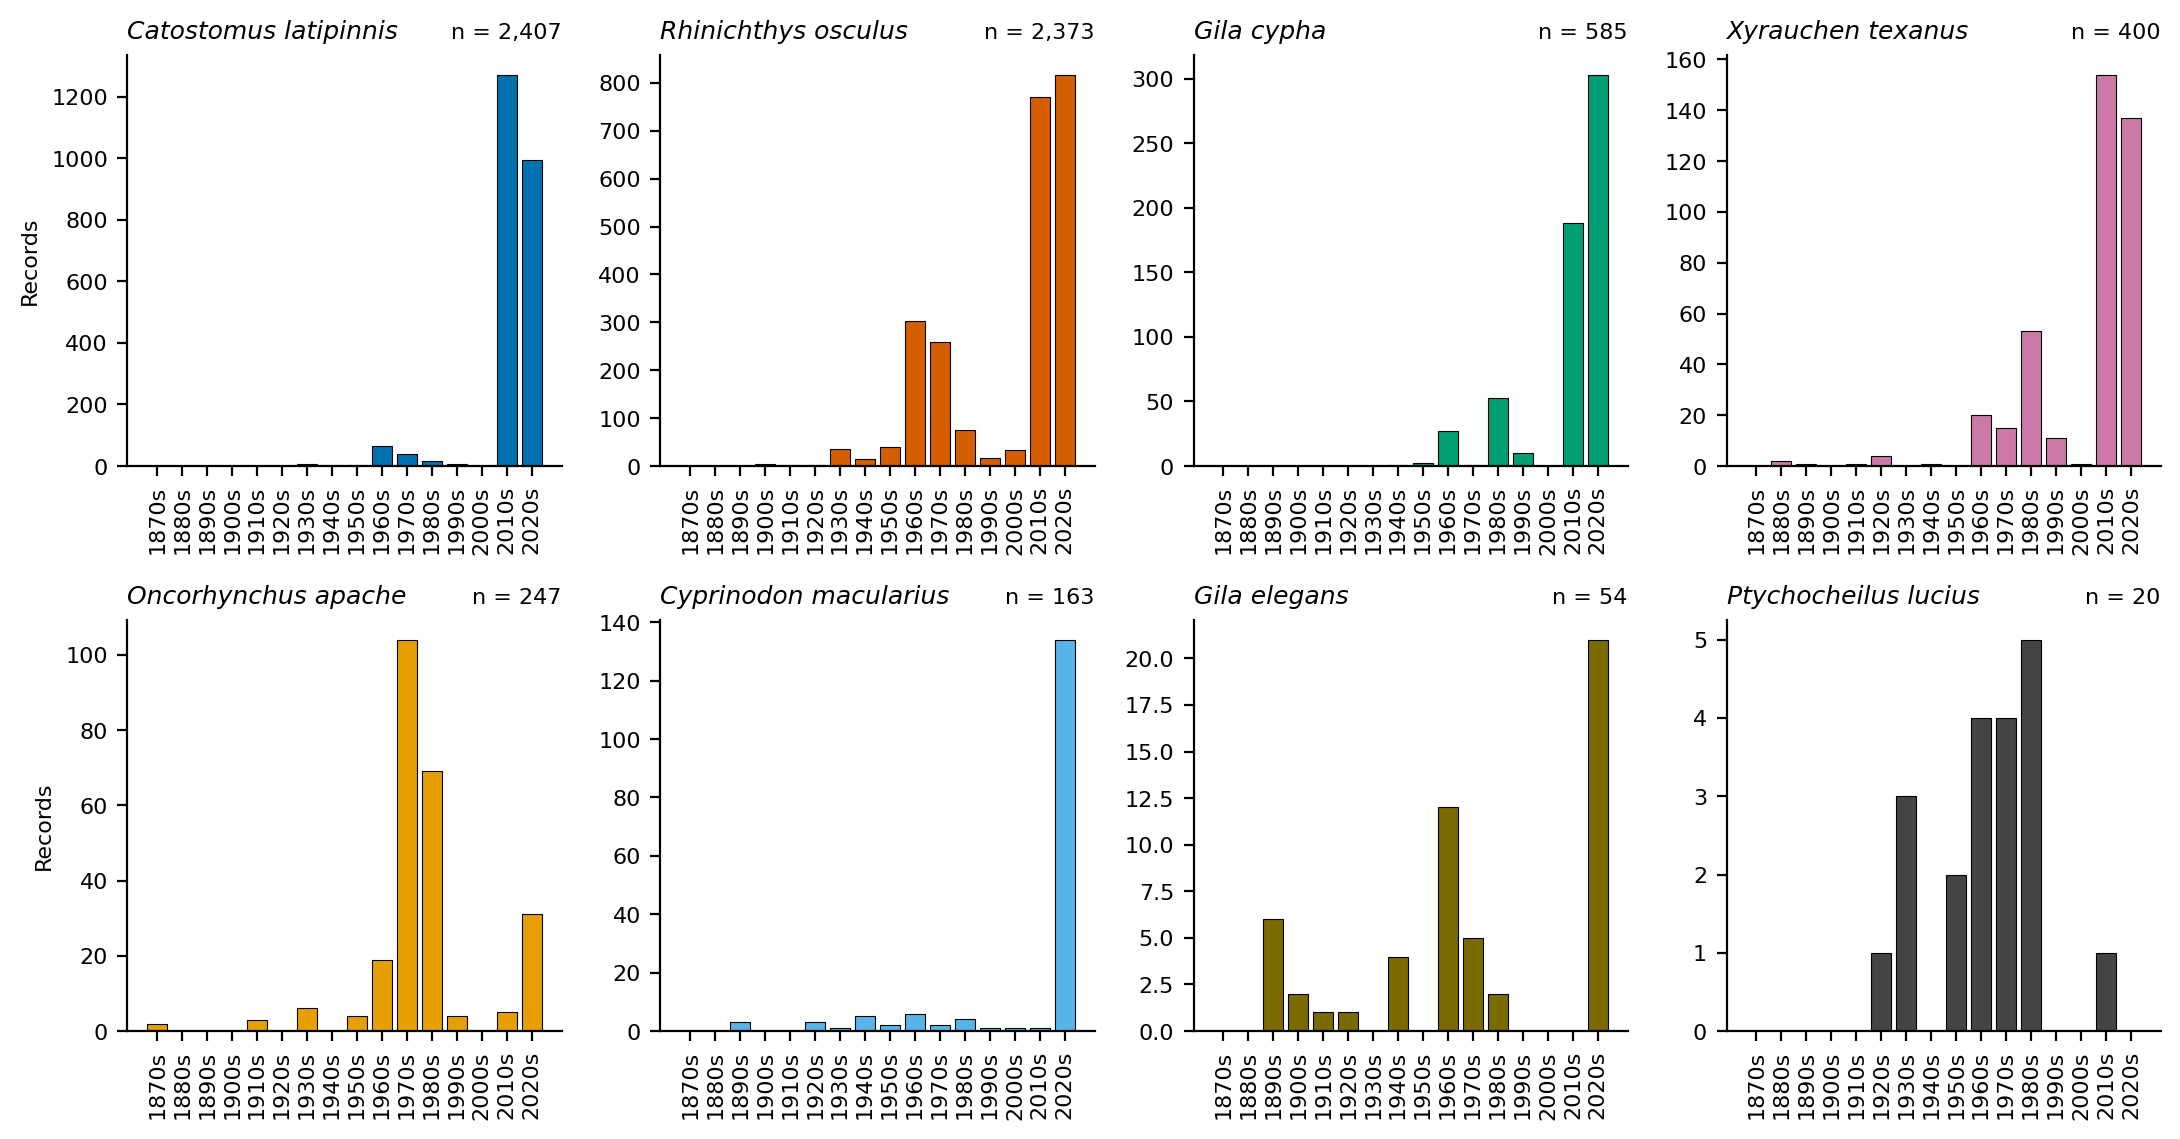
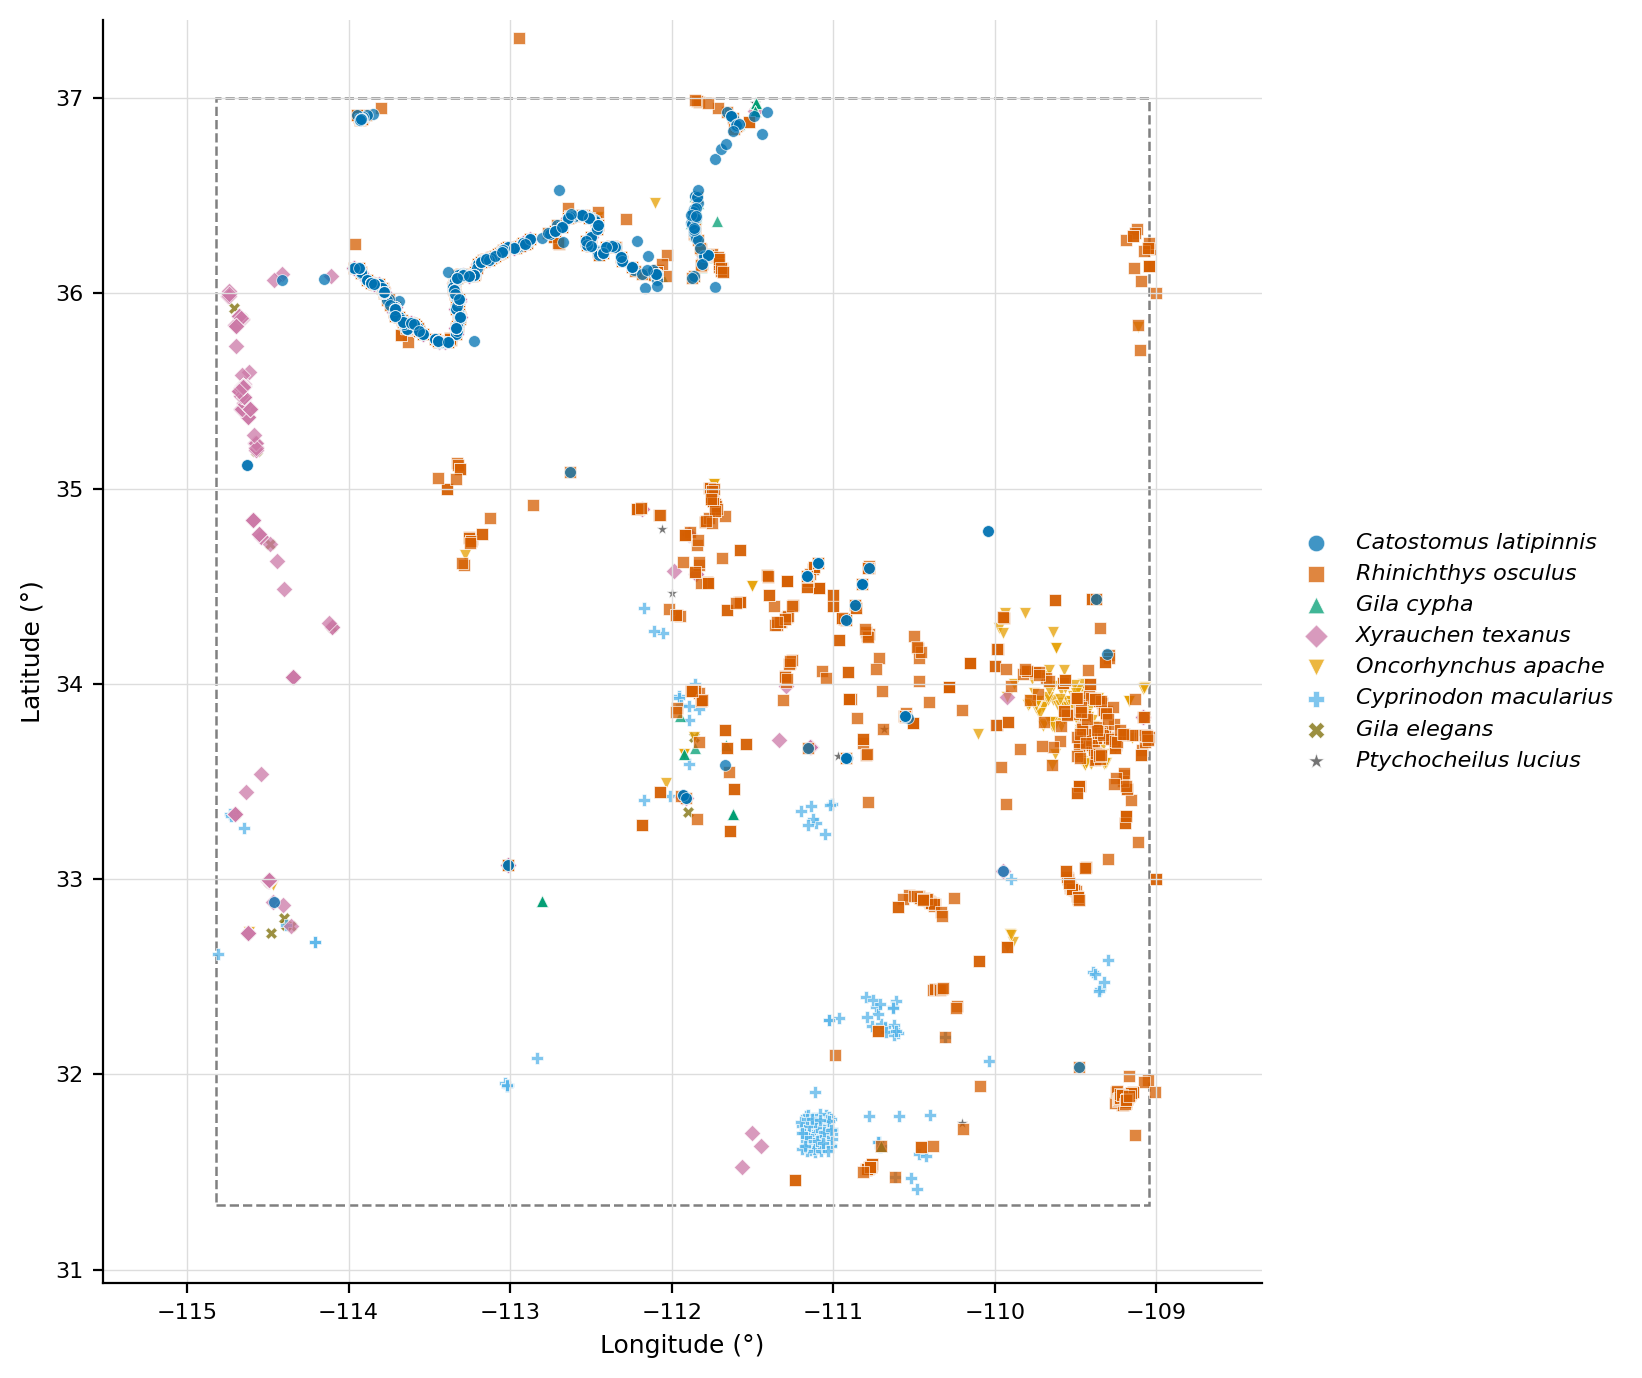

In [9]:
import base64
import datetime
import html
import json
import sqlite3
import pandas as pd
import folium
from folium.plugins import FastMarkerCluster, HeatMap
from IPython.display import HTML

DB_PATH = "az_fish.db"
AZ_W, AZ_E, AZ_S, AZ_N = -114.82, -109.045, 31.33, 37.0
MAP_X = (AZ_W - 0.7, AZ_E + 0.7)
MAP_Y = (AZ_S - 0.4, AZ_N + 0.4)

AUTHOR = "Sabian Henderson"
AFFILIATION = "Northern Arizona University"
PROJECT_TITLE = "Occurrence Records of Native Arizona Fishes in GBIF"
REPO_URL = ""
NOTES = ""

COMMON = {
    "Gila cypha": "Humpback chub",
    "Xyrauchen texanus": "Razorback sucker",
    "Gila elegans": "Bonytail",
    "Ptychocheilus lucius": "Colorado pikeminnow",
    "Catostomus latipinnis": "Flannelmouth sucker",
    "Rhinichthys osculus": "Speckled dace",
    "Oncorhynchus apache": "Apache trout",
    "Cyprinodon macularius": "Desert pupfish",
}
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#7A6A00", "#444444"]

# Updated as requested: keeping only Esri World Topographic and Esri Satellite
BASEMAPS = [
    ("Esri World Topographic",
     "https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
     "Tiles &copy; Esri", None),
    ("Esri Satellite",
     "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
     "Tiles &copy; Esri &mdash; Source: Esri, Maxar, Earthstar Geographics, and the GIS User Community", None),
]

CSS = """
body{font-family:Georgia,"Times New Roman",serif;max-width:780px;margin:2.5rem auto;padding:0 1.2rem;
     line-height:1.55;color:#111;font-size:17px}
h1{font-size:1.75rem;text-align:center;margin:0 0 .4rem;line-height:1.25}
.byline{text-align:center;margin:0}
.status{text-align:center;font-size:.9rem;color:#555;font-style:italic;margin:.2rem 0 0}
.abstract{border-top:1px solid #999;border-bottom:1px solid #999;padding:.8rem 0;margin:1.6rem 0}
.abstract b{font-variant:small-caps;letter-spacing:.03em}
h2{font-size:1.2rem;border-bottom:1px solid #ccc;padding-bottom:.2rem;margin-top:2.2rem}
table{border-collapse:collapse;width:100%;font-size:.88rem}
thead th{border-top:2px solid #111;border-bottom:1px solid #111;text-align:left;padding:.35rem .5rem}
tbody td{padding:.3rem .5rem;vertical-align:top}
tbody tr:last-child td{border-bottom:2px solid #111}
.num{text-align:right}
.cap{font-size:.9rem;margin:1.3rem 0 .35rem;break-after:avoid;page-break-after:avoid}
figure{margin:1.6rem 0}
figure img{width:100%;height:auto}
.map{width:100%;height:560px;border:1px solid #999}
figcaption{font-size:.9rem;margin-top:.4rem}
.wide{overflow-x:auto}
.refs{font-size:.92rem;padding-left:1.2rem}
footer{margin-top:2.5rem;font-size:.82rem;color:#555;border-top:1px solid #ccc;padding-top:.6rem}
@media print{body{margin:1cm;font-size:11pt}figure,table{page-break-inside:avoid}}
"""

def load_records(conn):
    return pd.read_sql_query(
        "SELECT o.*, s.query_name AS species FROM occurrences o JOIN species s USING (taxon_key)",
        conn,
    )

def species_by_count(df):
    return df["species"].value_counts().index.tolist()

def outside_box(df):
    g = df.dropna(subset=["latitude", "longitude"])
    return g[(g["longitude"] < AZ_W) | (g["longitude"] > AZ_E) |
             (g["latitude"] < AZ_S) | (g["latitude"] > AZ_N)]

def n_clipped(df):
    g = df.dropna(subset=["latitude", "longitude"])
    return int(((g["longitude"] < MAP_X[0]) | (g["longitude"] > MAP_X[1]) |
                (g["latitude"] < MAP_Y[0]) | (g["latitude"] > MAP_Y[1])).sum())

def build_map(df):
    g = df.dropna(subset=["latitude", "longitude"])
    order = species_by_count(g)
    m = folium.Map(location=[34.2, -111.7], zoom_start=6, tiles=None, control_scale=True)
    for i, (name, url, attr, subs) in enumerate(BASEMAPS):
        kw = {"subdomains": subs} if subs else {}
        folium.TileLayer(tiles=url, attr=attr, name=name, overlay=False, control=True,
                         show=(i == 0), max_zoom=19, **kw).add_to(m)

    heat = folium.FeatureGroup(name="Record density (heat map, all species)", show=True)
    HeatMap(g[["latitude", "longitude"]].values.tolist(), radius=11, blur=15, min_opacity=0.35).add_to(heat)
    heat.add_to(m)

    for i, sp in enumerate(order):
        color = PALETTE[i % len(PALETTE)]
        sub = g[g["species"] == sp]
        rows = []
        for r in sub.itertuples():
            basis = r.basis_of_record.replace("_", " ").lower() if isinstance(r.basis_of_record, str) else "unknown"
            rows.append([round(float(r.latitude), 5), round(float(r.longitude), 5),
                         "unknown" if pd.isna(r.year) else int(r.year), basis])
        label = f"{sp} ({COMMON.get(sp, '')}, n={len(sub):,})"
        callback = """
        function (row) {
            var icon = L.divIcon({className: '', iconSize: [13, 13],
                html: '<div style="background:%s;width:11px;height:11px;border-radius:50%%;border:1.5px solid #fff;box-shadow:0 0 2px #000"></div>'});
            var marker = L.marker(new L.LatLng(row[0], row[1]), {icon: icon});
            marker.bindPopup("<i>" + %s + "</i><br>Year: " + row[2] + "<br>Record type: " + row[3]);
            return marker;
        }
        """ % (color, json.dumps(sp))
        grp = folium.FeatureGroup(name=label, show=False)
        grp.add_child(FastMarkerCluster(data=rows, callback=callback))
        m.add_child(grp)

    items = "".join(
        f'<div><span style="display:inline-block;width:10px;height:10px;border-radius:50%;background:{PALETTE[i % len(PALETTE)]};'
        f'margin-right:6px"></span><i>{html.escape(sp)}</i></div>' for i, sp in enumerate(order)
    )
    legend = (
        '<div style="position:fixed;bottom:24px;left:12px;z-index:9999;background:rgba(255,255,255,.92);'
        'padding:8px 10px;border:1px solid #999;border-radius:4px;font:12px Georgia,serif;line-height:1.5">'
        '<b>Species layers</b> (toggle at top right)' + items +
        '<div style="margin-top:4px;color:#555">Heat layer = density of records, not abundance</div></div>'
    )
    m.get_root().html.add_child(folium.Element(legend))
    m.fit_bounds([[AZ_S, AZ_W], [AZ_N, AZ_E]])
    folium.LayerControl(collapsed=False, position="topright").add_to(m)
    return m.get_root().render()

def embed(path):
    try:
        with open(path, "rb") as f:
            return "data:image/png;base64," + base64.b64encode(f.read()).decode()
    except FileNotFoundError:
        raise SystemExit(f"{path} not found - run cell aafffc60 before this cell.")

def table_html(headers, rows, num_cols=()):
    th = "".join(f'<th class="{"num" if i in num_cols else ""}">{h}</th>' for i, h in enumerate(headers))
    body = "".join(
        "<tr>" + "".join(f'<td class="{"num" if i in num_cols else ""}">{c}</td>' for i, c in enumerate(r)) + "</tr>"
        for r in rows
    )
    return f'<div class="wide"><table><thead><tr>{th}</tr></thead><tbody>{body}</tbody></table></div>'

def fmt_year(x):
    return str(int(x)) if pd.notna(x) else "&ndash;"

def cmd_site():
    conn = sqlite3.connect(DB_PATH)
    df = load_records(conn)
    sources = pd.read_sql_query(
        """
        SELECT COALESCE(d.title, o.dataset_key) AS title, COUNT(*) AS n
        FROM occurrences o LEFT JOIN datasets d USING (dataset_key)
        GROUP BY o.dataset_key ORDER BY COUNT(*) DESC
        """,
        conn,
    )
    conn.close()
    if df.empty:
        print("Database is empty - run fetch first.")
        return

    n, today = len(df), datetime.date.today().isoformat()
    n_sp = df["species"].nunique()
    years = df["year"].dropna()
    span = f"{int(years.min())}&ndash;{int(years.max())}" if not years.empty else "n/a"
    n_noyear = int(df["year"].isna().sum())
    counts = df["species"].value_counts()
    top_sp, top_n = counts.index[0], int(counts.iloc[0])
    n_ds = len(sources)
    n_out = len(outside_box(df))
    n_clip = n_clipped(df)
    map_html = build_map(df)
    with open("map.html", "w", encoding="utf-8") as f:
        f.write(map_html)
    basis = df["basis_of_record"].fillna("UNKNOWN").value_counts()
    pct_spec = 100 * basis.get("PRESERVED_SPECIMEN", 0) / n
    decade_tot = (years // 10 * 10).astype(int).value_counts()
    peak_dec, peak_n = int(decade_tot.idxmax()), int(decade_tot.max())

    abstract = (
        f"I compiled {n:,} georeferenced occurrence records for {n_sp} native Arizona fish species from the "
        f"Global Biodiversity Information Facility (GBIF), spanning {span}. "
        f"<i>{html.escape(top_sp)}</i> has the most records ({top_n:,}; {100 * top_n / n:.0f}% of the total). "
        f"Records come from {n_ds} contributing datasets"
        + (f", and {pct_spec:.0f}% are preserved specimens" if pct_spec > 0 else "")
        + ". This page summarizes where and when each species has been recorded and describes limits on "
        "interpreting record counts."
    )

    sp_rows = []
    for sp in counts.index:
        g = df[df["species"] == sp]
        sp_rows.append([
            f'<i style="white-space:nowrap">{html.escape(sp)}</i>', html.escape(COMMON.get(sp, "")), str(int(g["taxon_key"].iloc[0])),
            f"{len(g):,}", fmt_year(g["year"].min()), fmt_year(g["year"].max()),
        ])
    t1 = table_html(["Species", "Common name", "GBIF key", "Records", "First year", "Last year"],
                    sp_rows, num_cols=(2, 3, 4, 5))

    b_rows = [[html.escape(b.replace("_", " ").capitalize()), f"{c:,}", f"{100 * c / n:.1f}%"]
              for b, c in basis.items()]
    t2 = table_html(["Basis of record", "Records", "Share"], b_rows, num_cols=(1, 2))

    s_rows = [[html.escape(str(r.title)), f"{int(r.n):,}"] for r in sources.head(10).itertuples()]
    t3 = table_html(["Source dataset (top 10)", "Records"], s_rows, num_cols=(1,))
    more = f" The remaining {n_ds - 10} datasets contribute fewer records each." if n_ds > 10 else ""

    notes = ""
    if NOTES.strip():
        paras = "".join(f"<p>{html.escape(p)}</p>" for p in NOTES.strip().split("\n\n"))
        notes = f"<h2>4. Discussion</h2>{paras}"
    lim_no = 5 if notes else 4

    repo = f' Code: <a href="{html.escape(REPO_URL)}">{html.escape(REPO_URL)}</a>.' if REPO_URL else ""
    page = f"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>{html.escape(PROJECT_TITLE)}</title><style>{CSS}</style></head><body>
<h1>{html.escape(PROJECT_TITLE)}</h1>
<p class="byline">{html.escape(AUTHOR)} &middot; {html.escape(AFFILIATION)}</p>
<p class="status">Independent student project &middot; not peer reviewed &middot; data accessed {today}</p>

<div class="abstract"><b>Summary.</b> {abstract}</div>

<h2>1. Question</h2>
<p>Where and when have native Arizona fishes been recorded, and how do the number and distribution of
records differ between species and across decades?</p>

<h2>2. Data and methods</h2>
<p>Occurrence records were retrieved from the GBIF API (<code>occurrence/search</code>) for each species in
Table 1, restricted to records in Arizona, USA with coordinates. Each name was matched to the GBIF taxonomic
backbone; searches by taxon key also return records filed under synonyms and subordinate taxa. Records were
stored in a SQLite database and analyzed in Python (requests, pandas, matplotlib). {n_noyear:,} records lack
a year and are omitted from Figure 1.</p>
<p class="cap"><b>Table 1.</b> Study species and number of GBIF records retrieved.</p>
{t1}

<h2>3. Results</h2>
<p>Across all species, record numbers are highest in the {peak_dec}s ({peak_n:,} records). Records per
species are very unequal, so Figure 1 uses a separate y-axis for each panel.</p>
<figure><img src="{embed('records_by_decade.png')}" alt="Records per decade for each species">
<figcaption><b>Figure 1.</b> Number of GBIF records per decade for each species. Note the different
y-axis scales.</figcaption></figure>
<figure><img src="{embed('record_locations.png')}" alt="Map of record locations by species">
<figcaption><b>Figure 2.</b> Locations of georeferenced records. The dashed rectangle is the approximate
bounding box of Arizona; no state outline or river layer is drawn. {n_out:,} records lie outside the box
({n_clip:,} of them beyond the plot margins and not drawn); these may reflect coordinate errors or generalized
locations.</figcaption></figure>
<figure><iframe class="map" title="Interactive map of GBIF records" loading="lazy"
srcdoc="{html.escape(map_html, quote=True)}"></iframe>
<figcaption><b>Figure 3.</b> Interactive map (pan, zoom, and use the layer box at top right). The heat layer
shows where records are concentrated, which reflects survey effort as well as fish; switch on a species layer to
see its individual records, which cluster at low zoom. Base maps: Esri.</figcaption></figure>
<p class="cap"><b>Table 2.</b> Records by basis of record (how the occurrence was documented).</p>
{t2}
<p class="cap"><b>Table 3.</b> Datasets contributing the most records.{more}</p>
{t3}

{notes}
<h2>{lim_no}. Limitations</h2>
<ul>
<li>Record counts reflect where and when people looked, not abundance; more records in a decade can mean more
survey effort or digitization of museum collections.</li>
<li>Coordinates for some protected species may be generalized by data providers, and older records can have
uncertain locations. Records were not filtered by coordinate uncertainty.</li>
<li>Records come from the GBIF search API without de-duplication across datasets, so the same observation
could appear more than once.</li>
</ul>

<h2>{lim_no + 1}. Data availability</h2>
<p>All data are from GBIF and its contributing datasets (Table 3). The database and analysis code are
reproducible from the script that generated this page.{repo}</p>
<h2>References</h2>
<ol class="refs"><li>GBIF.org. <i>GBIF Occurrence Data</i>. https://www.gbif.org (records accessed via
https://api.gbif.org/v1 on {today}). For formal citation, use the DOI of a GBIF occurrence download.</li></ol>
<footer>Generated {today} from az_fish.db by az_fish.py.</footer>
</body></html>"""
    with open("index.html", "w", encoding="utf-8") as f:
        f.write(page)
    print("Wrote index.html (figures embedded) - open it in your browser, or display it in the notebook.")

cmd_site()

with open("index.html", "r", encoding="utf-8") as f:
    html_content = f.read()

HTML('<iframe srcdoc="' + html.escape(html_content) + '" style="width: 100%; height: 800px; border: none;"></iframe>')